# Global Reading Atlas
### Reading, listening and genres in public survey data

A reproducible analytical companion to the dashboard. **Evidence snapshot: 8 October 2026.**
Survey years range from 2011 to 2025. This report measures published survey observations;
the evidence supports a comparable European section and distinct national profiles.

## tl;dr

- **32 European countries have usable 2022 observations.** Book participation ranges from
  **29.2% in Albania to 80.6% in Switzerland**.
  The official EU aggregate is **52.8%**. Eurostat includes audiobooks in this measure.
- **Women have higher reported participation in all 32 assessable countries.**
  Higher education is also associated with higher participation within every assessable country;
  the median tertiary-minus-low-education gap is **38.6 percentage points**.
  These subgroup patterns describe association.
- **US audiobook participation rose from 11% in 2011 to 23% in 2021** in the phone-survey period.
  The **26% result in 2025** uses a changed survey mode and is shown separately.
- **Canadian reported fiction genres vary by format:** mysteries/thrillers lead the reported
  print, ebook and audiobook lists. History leads its separate nonfiction lists. Singapore adds a broader mixed-material genre view.
  The two genre sources have different populations and questions.

**Reading rule:** percentages with different denominators or recall periods stay in separate views.
No all-world participation estimate, causal model, or survey-design confidence interval is inferred.

## Context & Methods

The central question is how book use differs by geography, format and demographic group,
and what public surveys reveal about genres. The analysis has three distinct units:

| Question | Observation unit | Scope |
|:--|:--|:--|
| European participation | Country × 2022 × population group | Eurostat EU-SILC; age 16+ |
| Format use | Country × survey year × format × stated population | Separate survey profiles |
| Genre preferences | Country × format × genre × stated reader base | Canada and Singapore, separately |

### Key Assumptions

1. Eurostat participation is `100 − percentage reporting zero books`; the source includes print,
   ebooks and audiobooks and excludes school textbooks and work manuals. It cannot identify
   listening separately from reading.
2. Demographic gaps subtract percentages for the same country, year, age scope and education scope.
   Groups are never summed. An unweighted country median describes this observed country set;
   it is not a population-weighted European rate.
3. Source flags matter: unreliable values (`u`) and missing observations remain missing.
   Published estimated values (`e`) remain identified. Germany is retained in data, excluded
   from numerical rankings, and never filled with zero.
4. Format use and genre choices overlap. Genre percentages represent selecting a category within
   the reported survey base, not market share or the proportion of all books consumed.
5. The source files contain aggregate survey tables. National respondent microdata, design
   weights and subgroup sample sizes are unavailable here. No valid design-based uncertainty,
   significance test or individual-level effect can be calculated from these tables.

### 1. Load the reproducible environment

This notebook reads the project's cached, traceable observations. It makes no live API call.
Run the source refresh separately when you want a new evidence snapshot, then rerun all cells.
The project root is found from the working directory and its parents, so a notebook editor can launch
the notebook from any directory inside the project.

In [1]:
from pathlib import Path
import os
import json
import hashlib
from decimal import Decimal, ROUND_HALF_UP
import textwrap
from importlib.metadata import version

def find_project_root():
    explicit = os.environ.get("GRA_PROJECT_ROOT")
    candidates = ([Path(explicit)] if explicit else []) + [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / "data/processed/europe_participation.csv").is_file():
            return candidate.resolve()
    raise FileNotFoundError("Start the notebook inside Global Reading Atlas, or set GRA_PROJECT_ROOT.")

ROOT = find_project_root()
OUTPUT_ROOT = Path(os.environ.get("GRA_NOTEBOOK_OUTPUT_ROOT", ROOT)).resolve()
FIGURES = OUTPUT_ROOT / "outputs/notebook_figures"
FIGURES.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(OUTPUT_ROOT / "work/matplotlib"))

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr
from IPython.display import display, HTML, Markdown

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#bec7cd", "axes.labelcolor": "#24333c",
    "xtick.color": "#44535d", "ytick.color": "#24333c",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "grid.color": "#e6ebee", "grid.linewidth": 0.8,
    "savefig.facecolor": "white", "savefig.dpi": 180,
})
COLORS = {"Print": "#25658c", "Ebook": "#a98026", "Audiobook": "#d36b3d"}
BLUE, GOLD, INK, GREY = "#25658c", "#a98026", "#24333c", "#778993"
figure_paths = []

def one_decimal(value):

    return str(Decimal(str(value)).quantize(Decimal("0.1"), rounding=ROUND_HALF_UP))

def finish_figure(fig, filename, source_note):

    fig.text(0.01, 0.015, source_note, ha="left", va="bottom", fontsize=9, color="#586a75")
    path = FIGURES / f"{filename}.png"
    fig.savefig(path, bbox_inches="tight")
    figure_paths.append(path)
    display(fig)
    plt.close(fig)

print("Cached observations loaded from the Global Reading Atlas project.")

Cached observations loaded from the Global Reading Atlas project.


## Data
### 2. Read and check the analytical tables

The checks below verify the notebook's actual input grain, percentage range and calculation
identities. They do not validate the original survey design or make unlike national surveys
comparable. Each source table and retained source URL can be inspected in the repository.

In [2]:
FILES = {
    "Europe baseline": "europe_participation.csv",
    "Europe demographics": "europe_demographics.csv",
    "Gender gaps": "gender_gaps.csv",
    "EU benchmark": "eu_benchmark.csv",
    "US format history": "us_formats.csv",
    "National format profiles": "format_profiles.csv",
    "National genre profiles": "genre_profiles.csv",
}
tables = {label: pd.read_csv(ROOT / "data/processed" / name) for label, name in FILES.items()}
europe = tables["Europe baseline"]
demographics = tables["Europe demographics"]
gender_source = tables["Gender gaps"]
eu_benchmark = float(tables["EU benchmark"].participation.iloc[0])
us = tables["US format history"]
formats = tables["National format profiles"]
genres = tables["National genre profiles"]

assert not europe.duplicated(["country_iso3"]).any()
assert not demographics.duplicated(["country_iso3", "year", "sex", "age", "isced11"]).any()
assert not us.duplicated(["country_iso3", "year", "format"]).any()
assert not formats.duplicated(["country_iso3", "year", "format_label", "denominator"]).any()
assert not genres.duplicated(["country_iso3", "year", "format_label", "genre_scope", "genre", "denominator"]).any()
for frame in tables.values():
    if "participation" in frame:
        assert frame.participation.dropna().between(0, 100).all()
reliable_baseline = europe.dropna(subset=["participation"])
assert np.allclose(reliable_baseline.participation, 100 - reliable_baseline.nonreader_pct)
assert europe.loc[europe.participation.isna(), "country"].tolist() == ["Germany"]
assert demographics.loc[demographics.status_flag.fillna("").str.contains("u"), "participation"].isna().all()
assert len(reliable_baseline) == 32
canada_missing = genres[(genres.country_iso3 == "CAN") & genres.participation.isna()]
assert len(canada_missing) == 2
assert canada_missing.groupby("genre_scope").size().eq(1).all()
assert canada_missing.genre.eq("Comics or Graphic Novels").all()
assert canada_missing.format_label.eq("Audiobook").all()

integrity = pd.DataFrame([
    {"Table": label, "Rows": len(frame),
     "Missing percentages": int(frame.participation.isna().sum()) if "participation" in frame else 0}
    for label, frame in tables.items()
])
display(integrity.style.hide(axis="index"))

Table,Rows,Missing percentages
Europe baseline,33,1
Europe demographics,1980,67
Gender gaps,33,0
EU benchmark,1,0
US format history,27,0
National format profiles,15,0
National genre profiles,66,2


### 3. Definitions and original evidence

Direct links below preserve the survey source. Eurostat data is cached from its dissemination
API. National observations were manually transcribed from the stated published tables; exact
question/page locators and denominator notes remain in the CSV rows.

In [3]:
eurostat_url = "https://ec.europa.eu/eurostat/databrowser/view/ilc_scp27/default/table"
source_rows = [{"Source": "Eurostat EU-SILC", "Survey years": "2022", "Evidence": "ilc_scp27; n_book=0, unit=PC",
                "Original evidence": f'<a href="{eurostat_url}">Eurostat table</a>'}]
for country, frame in formats.groupby("country", sort=True):
    row = frame.iloc[0]
    source_rows.append({"Source": f"{country} · {row.source_id}", "Survey years": str(row.year),
                        "Evidence": row.evidence_locator,
                        "Original evidence": f'<a href="{row.source_url}">Original survey/table</a>'})
source_table = pd.DataFrame(source_rows)
display(HTML(source_table.to_html(index=False, escape=False)))
display(Markdown("**Genre locators:** Canada: printed p.32, *Fiction genres read by format*. "
                 "Singapore: printed p.40, question B9. Canada nonfiction: printed p.33, *Non-fiction subjects read by format*. See each genre row's exact population and notes."))

Source,Survey years,Evidence,Original evidence
Eurostat EU-SILC,2022,"ilc_scp27; n_book=0, unit=PC",Eurostat table
Canada · booknet_ca,2024,Format preferences and frequency of reading,Original survey/table
Norway · ssb_no,2024,Article 2024 data; Fig.1–2,Original survey/table
Singapore · nlb_sg,2024,Printed p.50; B14,Original survey/table
Sweden · nordicom_se,2024,Printed pp.15–16; daily reach chart,Original survey/table
United States · pew_us,2025,Published Data table; 2025 row,Original survey/table


**Genre locators:** Canada: printed p.32, *Fiction genres read by format*. Singapore: printed p.40, question B9. Canada nonfiction: printed p.33, *Non-fiction subjects read by format*. See each genre row's exact population and notes.

## Results
### 4. European participation in 2022

This is the strongest geographically comparable section: the same Eurostat table, survey year,
baseline age and format definition. Countries are ordered by published point estimates; uncertainty
is unavailable, so this is not a significance ranking. The displayed geography includes EU members and other
countries covered by the survey. The dashed reference is the official EU27 aggregate.

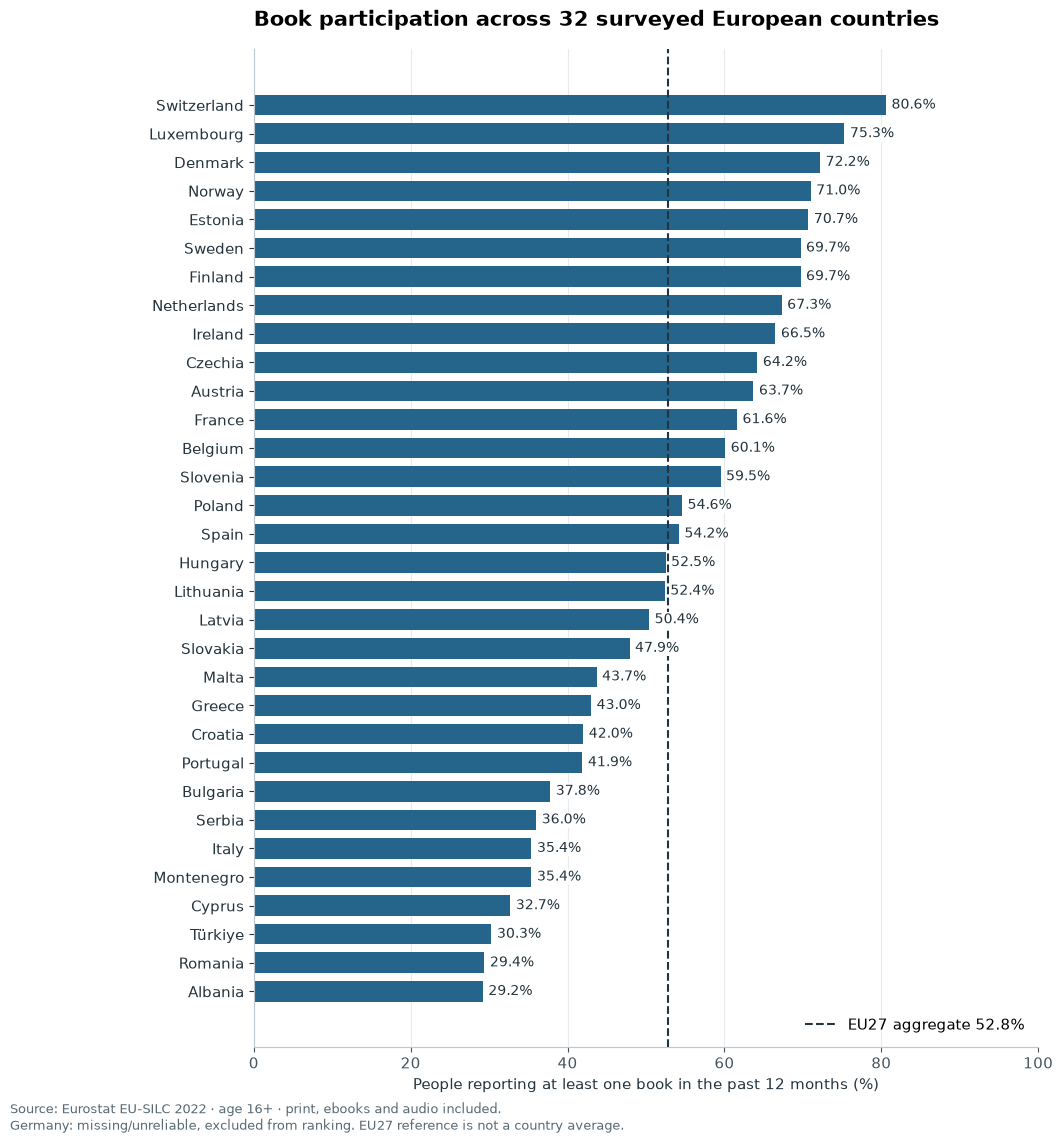

In [4]:
ranked = europe.dropna(subset=["participation"]).sort_values("participation", ascending=True)
fig, ax = plt.subplots(figsize=(10.6, 11.6))
ax.barh(ranked.country, ranked.participation, color=BLUE, height=0.72, zorder=2)
ax.axvline(eu_benchmark, color=INK, linewidth=1.5, linestyle="--", zorder=3,
           label=f"EU27 aggregate {eu_benchmark:.1f}%")
for position, value in enumerate(ranked.participation):
    ax.text(value + 0.7, position, f"{value:.1f}%", va="center", fontsize=10, color=INK,
            zorder=4, bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.7})
ax.set_xlim(0, 100)
ax.set_xlabel("People reporting at least one book in the past 12 months (%)")
ax.set_title("Book participation across 32 surveyed European countries", loc="left", pad=17)
ax.xaxis.grid(True, zorder=0)
ax.legend(loc="lower right", frameon=False)
fig.subplots_adjust(left=0.24, right=0.98, top=0.95, bottom=0.09)
finish_figure(fig, "01_europe_participation",
              "Source: Eurostat EU-SILC 2022 · age 16+ · print, ebooks and audio included.\n"
              "Germany: missing/unreliable, excluded from ranking. EU27 reference is not a country average.")

In [5]:
top = ranked.iloc[-1]
bottom = ranked.iloc[0]
observed_eu = ranked[ranked.scope == "EU member"]
display(Markdown(
    f"**Observed spread:** {top.country} {top.participation:.1f}% versus {bottom.country} "
    f"{bottom.participation:.1f}%, a {top.participation - bottom.participation:.1f} percentage point difference. "
    f"The observed set contains {len(observed_eu)} EU members and {len(ranked) - len(observed_eu)} other "
    f"surveyed countries. The unweighted country median is {ranked.participation.median():.1f}%; "
    f"it is distinct from the official EU aggregate of {eu_benchmark:.1f}%."
))
display(ranked.sort_values("participation", ascending=False)
        [["country", "participation", "scope", "reliability"]].head(6)
        .rename(columns={"country": "Country", "participation": "Participation (%)", "scope": "Scope",
                         "reliability": "Source status"}).style.hide(axis="index").format({"Participation (%)": "{:.1f}"}))

**Observed spread:** Switzerland 80.6% versus Albania 29.2%, a 51.4 percentage point difference. The observed set contains 26 EU members and 6 other surveyed countries. The unweighted country median is 53.4%; it is distinct from the official EU aggregate of 52.8%.

Country,Participation (%),Scope,Source status
Switzerland,80.6,Other surveyed country,Published
Luxembourg,75.3,EU member,Published
Denmark,72.2,EU member,Published
Norway,71.0,Other surveyed country,Published
Estonia,70.7,EU member,Published
Sweden,69.7,EU member,Published


### 5. The gender pattern within countries

This comparison fixes country, year, age 16+ and all education levels. The reported source
categories are women and men. Differences are percentage points, with no causal interpretation
or statistical significance claim.

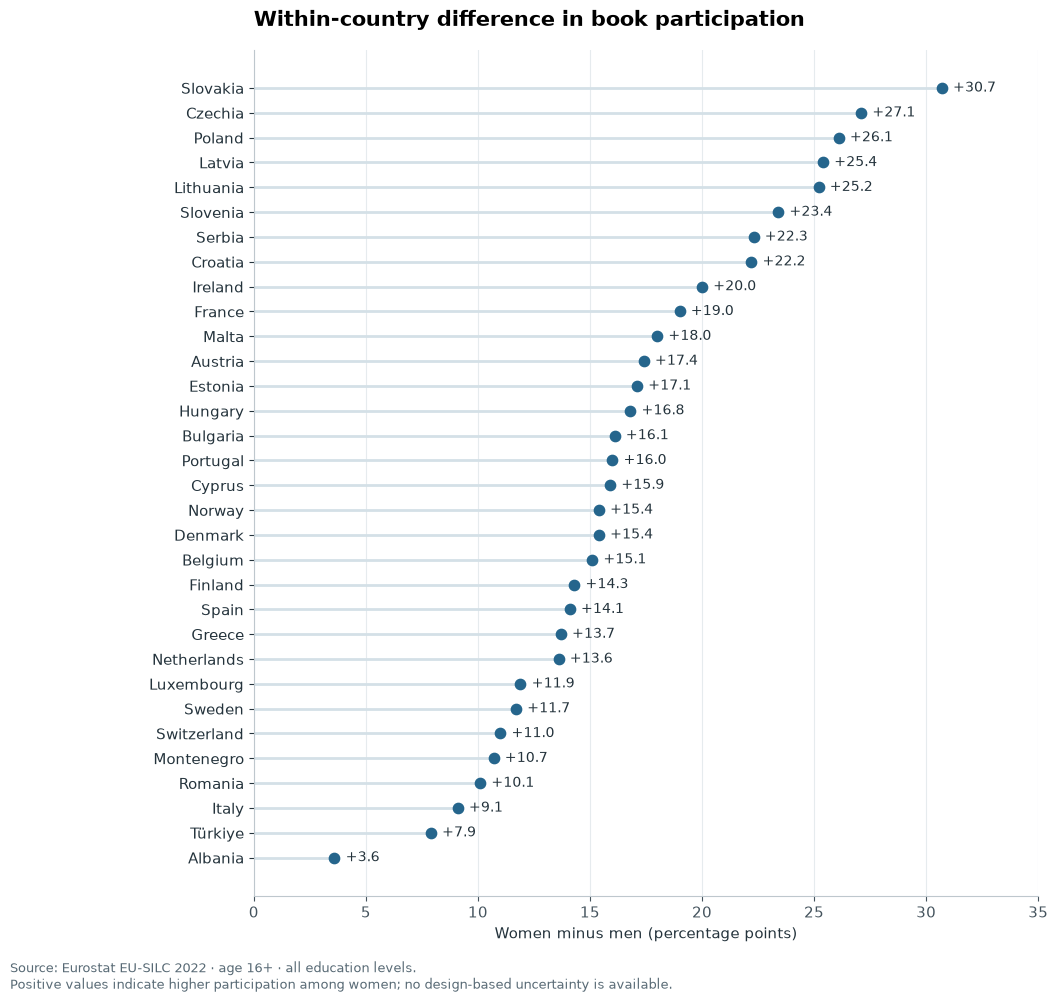

Women have higher reported participation in **32/32** assessable countries. The unweighted median gap is **15.9 percentage points**, with country gaps from 3.6 to 30.7 points.

In [6]:
gender_rows = demographics[(demographics.age == "Y_GE16") & (demographics.isced11 == "TOTAL")
                           & demographics.sex.isin(["F", "M"])]
gender = gender_rows.pivot(index=["country_iso3", "country"], columns="sex", values="participation")
gender["gap_pp"] = (gender.F - gender.M).round(1)
gender = gender.reset_index().dropna(subset=["gap_pp"])
reconciliation = gender.merge(gender_source[["country_iso3", "gap_pp"]], on="country_iso3", suffixes=("", "_source"))
assert np.allclose(reconciliation.gap_pp, reconciliation.gap_pp_source)
assert (gender.gap_pp > 0).all()

sorted_gender = gender.sort_values("gap_pp")
fig, ax = plt.subplots(figsize=(10.6, 10.2))
ax.hlines(sorted_gender.country, 0, sorted_gender.gap_pp, color="#d4e0e7", linewidth=2.0)
ax.scatter(sorted_gender.gap_pp, sorted_gender.country, color=BLUE, s=55, zorder=3)
for position, value in enumerate(sorted_gender.gap_pp):
    ax.text(value + 0.5, position, f"+{value:.1f}", va="center", fontsize=10, color=INK)
ax.set_xlim(0, 35)
ax.set_xlabel("Women minus men (percentage points)")
ax.set_title("Within-country difference in book participation", loc="left", pad=17)
ax.xaxis.grid(True)
fig.subplots_adjust(left=0.24, right=0.98, top=0.94, bottom=0.11)
finish_figure(fig, "02_gender_gaps",
              "Source: Eurostat EU-SILC 2022 · age 16+ · all education levels.\n"
              "Positive values indicate higher participation among women; no design-based uncertainty is available.")
display(Markdown(f"Women have higher reported participation in **{len(gender)}/{len(gender)}** assessable countries. "
                 f"The unweighted median gap is **{gender.gap_pp.median():.1f} percentage points**, "
                 f"with country gaps from {gender.gap_pp.min():.1f} to {gender.gap_pp.max():.1f} points."))

### 6. Age profiles within countries

Four non-overlapping age bands are shown independently. Each cell uses its own age-group
denominator. The heatmap follows overall participation order for lookup; its cells are never
combined into an unweighted overall rate. Darker cells mean higher participation.

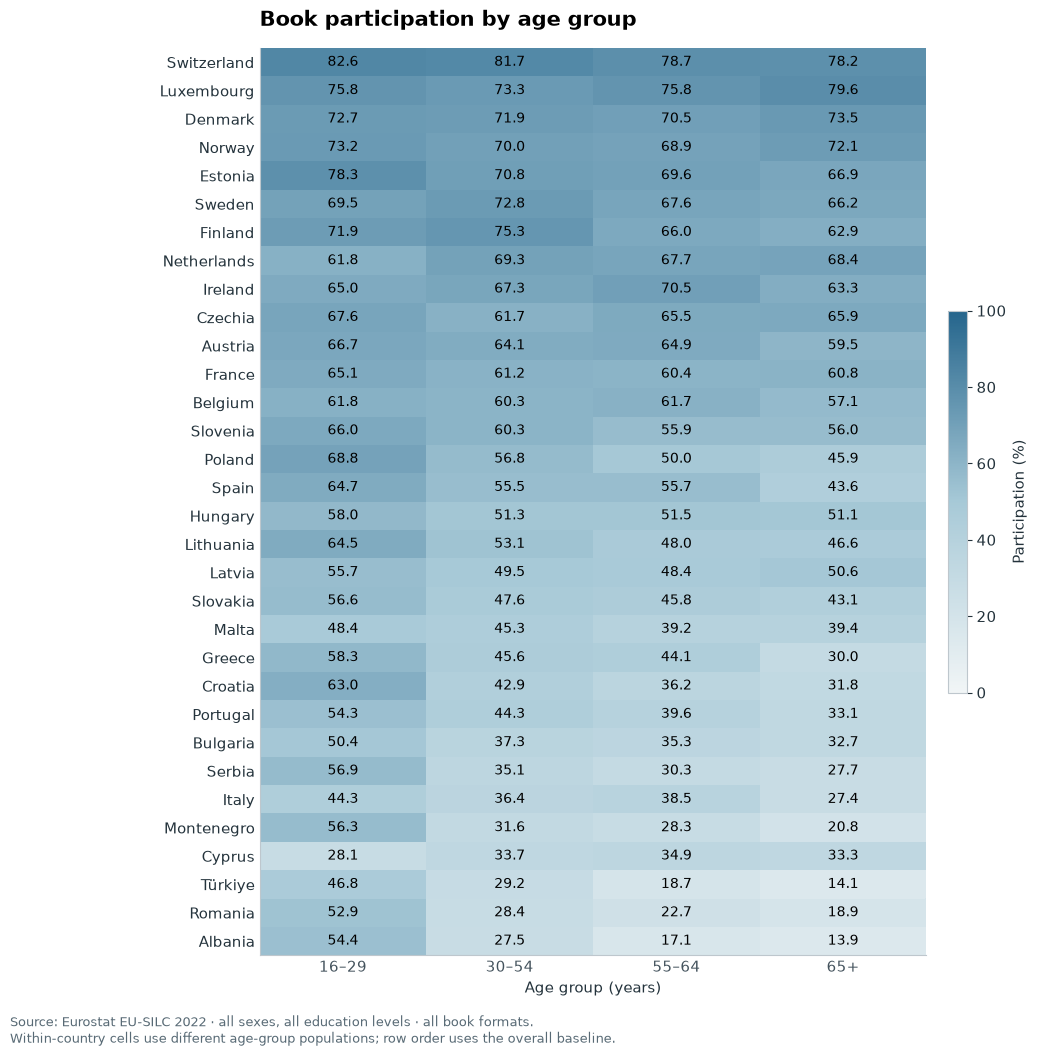

The 16–29 rate exceeds the 65+ rate in **28/32** assessable countries. The median within-country difference is **9.5 percentage points**. These age comparisons also reflect cohort and population composition.

In [7]:
age_order = ["Y16-29", "Y30-54", "Y55-64", "Y_GE65"]
age_labels = ["16–29", "30–54", "55–64", "65+"]
age_rows = demographics[(demographics.sex == "T") & (demographics.isced11 == "TOTAL")
                        & demographics.age.isin(age_order)]
age_matrix = age_rows.pivot(index="country", columns="age", values="participation")[age_order]
age_matrix = age_matrix.loc[ranked.sort_values("participation", ascending=False).country]
cmap = LinearSegmentedColormap.from_list("reading_participation", ["#f1f5f6", "#a7c9d7", "#25658c"])
cmap.set_bad("#eeeeee")
fig, ax = plt.subplots(figsize=(10.4, 10.8))
image = ax.imshow(age_matrix, cmap=cmap, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(4), age_labels)
ax.set_yticks(range(len(age_matrix)), age_matrix.index)
ax.set_xlabel("Age group (years)")
ax.set_title("Book participation by age group", loc="left", pad=16)
ax.tick_params(axis="both", length=0)
for y in range(age_matrix.shape[0]):
    for x in range(age_matrix.shape[1]):
        value = age_matrix.iloc[y, x]
        background = np.array(cmap(value / 100)[:3]) if pd.notna(value) else np.ones(3)
        linear_rgb = np.where(background <= 0.04045, background / 12.92, ((background + 0.055) / 1.055) ** 2.4)
        luminance = float(linear_rgb @ np.array([0.2126, 0.7152, 0.0722]))
        label_color = "white" if luminance < 0.179 else "black"
        ax.text(x, y, "—" if pd.isna(value) else f"{value:.1f}", ha="center", va="center",
                color=label_color, fontsize=10)
cbar = fig.colorbar(image, ax=ax, fraction=0.027, pad=0.03)
cbar.set_label("Participation (%)")
fig.subplots_adjust(left=0.25, right=0.93, top=0.94, bottom=0.1)
finish_figure(fig, "03_age_profiles",
              "Source: Eurostat EU-SILC 2022 · all sexes, all education levels · all book formats.\n"
              "Within-country cells use different age-group populations; row order uses the overall baseline.")

age_gap = (age_matrix["Y16-29"] - age_matrix["Y_GE65"]).dropna()
display(Markdown(f"The 16–29 rate exceeds the 65+ rate in **{int((age_gap > 0).sum())}/{len(age_gap)}** "
                 f"assessable countries. The median within-country difference is **{age_gap.median():.1f} "
                 "percentage points**. These age comparisons also reflect cohort and population composition."))

### 7. Exploratory statistics: is the education pattern sensitive to age scope?

A small paired analysis compares tertiary education (ISCED 5–8) with primary/lower-secondary
education or below (ISCED 0–2) in each country. We repeat the subtraction among people aged
30–54, rather than fitting an unsupported individual-level predictive model.

This narrows the age range but is **not an age-standardised or causal effect**. The two scopes
overlap, so they are compared as a sensitivity check and never pooled as independent observations.
Descriptive medians and rank correlation summarise the observed countries; p-values and confidence
intervals are omitted because countries are not a random survey sample and source survey design
information is unavailable.

In [8]:
def education_pairs(age_code):
    selected = demographics[(demographics.sex == "T") & (demographics.age == age_code)
                            & demographics.isced11.isin(["ED0-2", "ED5-8"])]
    paired = selected.pivot(index=["country_iso3", "country", "scope"], columns="isced11", values="participation")
    paired = paired.dropna(subset=["ED0-2", "ED5-8"])
    paired["gap_pp"] = (paired["ED5-8"] - paired["ED0-2"]).round(1)
    return paired.reset_index()

education_all = education_pairs("Y_GE16")
education_midlife = education_pairs("Y30-54")
paired_education = education_all[["country_iso3", "country", "scope", "gap_pp"]].merge(
    education_midlife[["country_iso3", "gap_pp"]], on="country_iso3", validate="one_to_one",
    suffixes=("_age16plus", "_age30to54"))
assert len(paired_education) == 32
assert (paired_education[["gap_pp_age16plus", "gap_pp_age30to54"]] > 0).all().all()
rank_agreement = spearmanr(paired_education.gap_pp_age16plus, paired_education.gap_pp_age30to54).statistic

leave_one_out = [spearmanr(part.gap_pp_age16plus, part.gap_pp_age30to54).statistic
                 for _, country in paired_education.iterrows()
                 for part in [paired_education[paired_education.country_iso3 != country.country_iso3]]]
summaries = []
for name, subset in [("All observed countries", paired_education),
                     ("Observed EU members only", paired_education[paired_education.scope == "EU member"])]:
    summaries.append({"Country set": name, "Countries": len(subset),
                      "Median gap, age 16+ (pp)": subset.gap_pp_age16plus.median(),
                      "Median gap, age 30–54 (pp)": subset.gap_pp_age30to54.median(),
                      "Positive in both scopes": int(((subset.gap_pp_age16plus > 0) & (subset.gap_pp_age30to54 > 0)).sum())})
display(pd.DataFrame(summaries).style.hide(axis="index").format({
    "Median gap, age 16+ (pp)": one_decimal, "Median gap, age 30–54 (pp)": one_decimal}))
display(Markdown(f"**Descriptive rank agreement:** Spearman ρ = {rank_agreement:.2f}. "
                 f"Leaving out one country at a time gives {min(leave_one_out):.2f}–{max(leave_one_out):.2f}. "
                 "This sensitivity range is not a confidence interval."))

Country set,Countries,"Median gap, age 16+ (pp)","Median gap, age 30–54 (pp)",Positive in both scopes
All observed countries,32,38.6,48.1,32
Observed EU members only,26,37.5,48.1,26


**Descriptive rank agreement:** Spearman ρ = 0.81. Leaving out one country at a time gives 0.79–0.85. This sensitivity range is not a confidence interval.

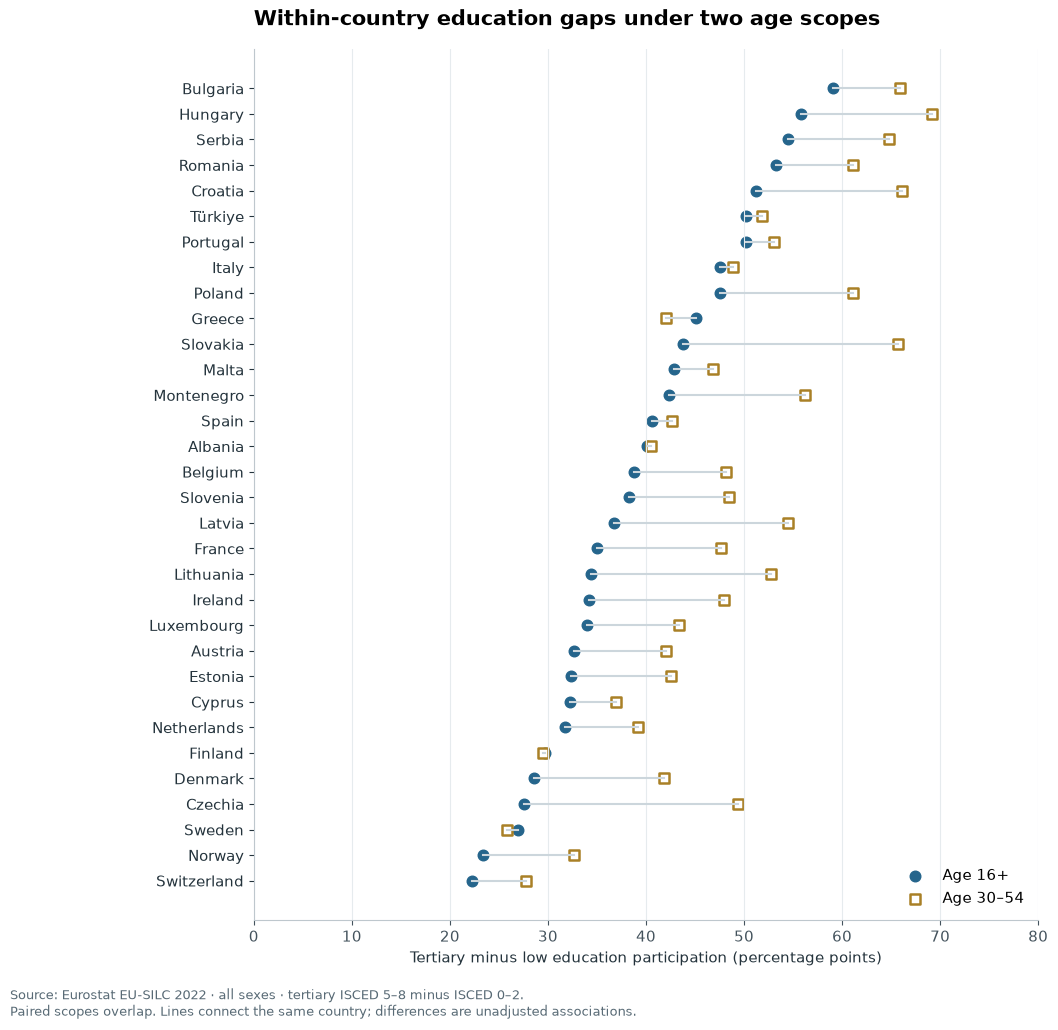

The education gap is positive in **all 32 countries in both scopes**. The median is 38.6 points for age 16+ and 48.1 points for age 30–54. The direction persists when the age scope narrows, but the gap size changes.

In [9]:
gap_order = paired_education.sort_values("gap_pp_age16plus")
fig, ax = plt.subplots(figsize=(10.6, 10.5))
for i, (_, row) in enumerate(gap_order.iterrows()):
    ax.plot([row.gap_pp_age16plus, row.gap_pp_age30to54], [i, i], color="#ccd6dc", linewidth=1.5)
ax.scatter(gap_order.gap_pp_age16plus, np.arange(len(gap_order)), s=58, color=BLUE,
           marker="o", label="Age 16+")
ax.scatter(gap_order.gap_pp_age30to54, np.arange(len(gap_order)), s=58,
           facecolors="white", edgecolors=GOLD, linewidths=1.8, marker="s", label="Age 30–54")
ax.set_yticks(range(len(gap_order)), gap_order.country)
ax.set_xlim(0, 80)
ax.set_xlabel("Tertiary minus low education participation (percentage points)")
ax.set_title("Within-country education gaps under two age scopes", loc="left", pad=17)
ax.xaxis.grid(True)
ax.legend(loc="lower right", frameon=False)
fig.subplots_adjust(left=0.24, right=0.98, top=0.94, bottom=0.11)
finish_figure(fig, "04_education_sensitivity",
              "Source: Eurostat EU-SILC 2022 · all sexes · tertiary ISCED 5–8 minus ISCED 0–2.\n"
              "Paired scopes overlap. Lines connect the same country; differences are unadjusted associations.")
display(Markdown(f"The education gap is positive in **all {len(paired_education)} countries in both scopes**. "
                 f"The median is {one_decimal(paired_education.gap_pp_age16plus.median())} points for age 16+ and "
                 f"{one_decimal(paired_education.gap_pp_age30to54.median())} points for age 30–54. "
                 "The direction persists when the age scope narrows, but the gap size changes."))

### 8. US formats: an observed trend and a survey-method break

Pew reports at least part of one book in each format during the previous 12 months among
US adults aged 18+. Respondents can use multiple formats. Survey years are irregular and
are plotted at their actual calendar positions. The 2025 mode changed from phone to a
combination of web and phone; its result is separated from the phone-period line.

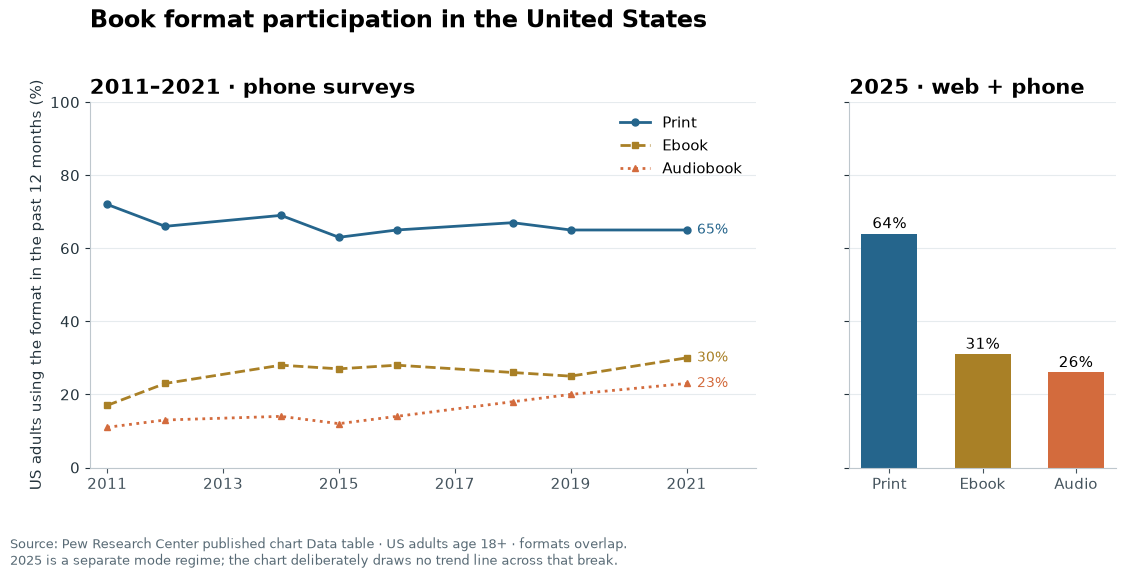

Audiobook participation increased **12 percentage points** from 2011 (11%) to 2021 (23%). The 2025 observation is 26%; a 2021-to-2025 change mixes behaviour and possible survey-mode effects.

In [10]:
phone = us[us.year <= 2021].sort_values("year")
changed_mode = us[us.year == 2025]
fig, axes = plt.subplots(1, 2, figsize=(11.4, 5.8), gridspec_kw={"width_ratios": [2.5, 1]}, sharey=True)
for label in ["Print", "Ebook", "Audiobook"]:
    series = phone[phone.format_label == label]
    axes[0].plot(series.year, series.participation,
                 marker={"Print": "o", "Ebook": "s", "Audiobook": "^"}[label],
                 linestyle={"Print": "-", "Ebook": "--", "Audiobook": ":"}[label],
                 markersize=5, linewidth=2, color=COLORS[label], label=label)
    axes[0].text(series.year.iloc[-1] + 0.18, series.participation.iloc[-1],
                 f"{int(series.participation.iloc[-1])}%", va="center", fontsize=10, color=COLORS[label])
axes[0].set_xlim(2010.7, 2022.2)
axes[0].set_xticks([2011, 2013, 2015, 2017, 2019, 2021])
axes[0].set_title("2011–2021 · phone surveys", loc="left")
axes[0].set_ylabel("US adults using the format in the past 12 months (%)")
axes[0].legend(loc="upper right", frameon=False)
latest = changed_mode.set_index("format_label").loc[["Print", "Ebook", "Audiobook"]]
axes[1].bar(range(3), latest.participation, color=[COLORS[label] for label in latest.index], width=0.6)
for x, value in enumerate(latest.participation):
    axes[1].text(x, value + 1.5, f"{value:.0f}%", ha="center", fontsize=11)
axes[1].set_xticks(range(3), ["Print", "Ebook", "Audio"])
axes[1].set_title("2025 · web + phone", loc="left")
for ax in axes:
    ax.set_ylim(0, 100)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
fig.suptitle("Book format participation in the United States", x=0.08, ha="left", fontsize=17, fontweight="bold")
fig.subplots_adjust(left=0.08, right=0.98, top=0.82, bottom=0.19, wspace=0.2)
finish_figure(fig, "05_us_formats",
              "Source: Pew Research Center published chart Data table · US adults age 18+ · formats overlap.\n"
              "2025 is a separate mode regime; the chart deliberately draws no trend line across that break.")
audiobook = us[us.format_label == "Audiobook"].set_index("year").participation
display(Markdown(f"Audiobook participation increased **{audiobook.loc[2021] - audiobook.loc[2011]:.0f} percentage "
                 f"points** from 2011 ({audiobook.loc[2011]:.0f}%) to 2021 ({audiobook.loc[2021]:.0f}%). "
                 f"The 2025 observation is {audiobook.loc[2025]:.0f}%; a 2021-to-2025 change mixes "
                 "behaviour and possible survey-mode effects."))

### 9. National format profiles, with their own denominators

Each panel is a separate reading question. Canada is an English-speaking online **reader sample**;
Singapore is the subset able to remember at least one book; Sweden and Norway measure
**average-day reach**; the US measures **annual participation among adults**. These panels
show local format patterns. Their heights do not establish a valid cross-country ranking.

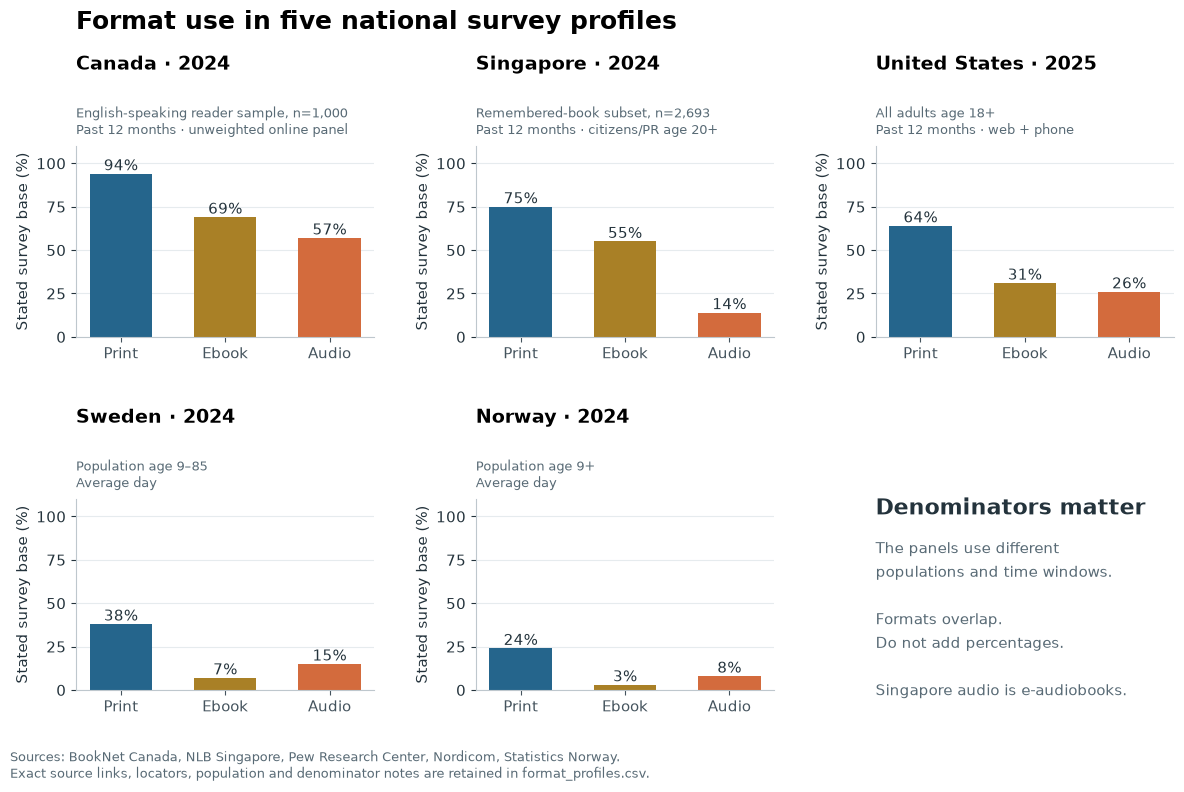

In [11]:
panel_settings = [
    ("CAN", "Canada · 2024", "English-speaking reader sample, n=1,000\nPast 12 months · unweighted online panel"),
    ("SGP", "Singapore · 2024", "Remembered-book subset, n=2,693\nPast 12 months · citizens/PR age 20+"),
    ("USA", "United States · 2025", "All adults age 18+\nPast 12 months · web + phone"),
    ("SWE", "Sweden · 2024", "Population age 9–85\nAverage day"),
    ("NOR", "Norway · 2024", "Population age 9+\nAverage day"),
]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (iso, title, subtitle) in zip(axes.flat, panel_settings):
    profile = formats[formats.country_iso3 == iso].set_index("format_label").loc[["Print", "Ebook", "Audiobook"]]
    ax.bar(range(3), profile.participation, color=[COLORS[label] for label in profile.index], width=0.6)
    for x, value in enumerate(profile.participation):
        ax.text(x, value + 2, f"{value:.0f}%", ha="center", fontsize=11, color=INK)
    ax.set_xticks(range(3), ["Print", "Ebook", "Audio"])
    ax.set_ylim(0, 110)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.set_ylabel("Stated survey base (%)")
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    ax.set_title(title, loc="left", fontsize=14, pad=55)
    ax.text(0, 1.04, subtitle, transform=ax.transAxes, ha="left", va="bottom", fontsize=9.2, color="#586a75")
axes.flat[-1].axis("off")
axes.flat[-1].text(0, 0.92, "Denominators matter", fontsize=16, fontweight="bold", color=INK)
axes.flat[-1].text(0, 0.8, "The panels use different\npopulations and time windows.\n\nFormats overlap.\nDo not add percentages.\n\nSingapore audio is e-audiobooks.",
                  va="top", fontsize=11, color="#586a75", linespacing=1.55)
fig.subplots_adjust(left=0.065, right=0.98, top=0.81, bottom=0.13, hspace=0.85, wspace=0.34)
fig.suptitle("Format use in five national survey profiles", x=0.065, y=0.98, ha="left", fontsize=18, fontweight="bold")
finish_figure(fig, "06_national_format_profiles",
              "Sources: BookNet Canada, NLB Singapore, Pew Research Center, Nordicom, Statistics Norway.\n"
              "Exact source links, locators, population and denominator notes are retained in format_profiles.csv.")

### 10. Canadian fiction genres by format

BookNet Canada's 2024 survey uses an unweighted English-speaking adult online panel with a
recruited reader base. This genre question concerns fiction readers within each format, with
up to three selections. Exact format-fiction subgroup sample sizes are unpublished in the
extracted table. The published dash for audiobook comics/graphic novels is missing, not zero.
Labels below retain the source's categories, including “Chick Lit”.

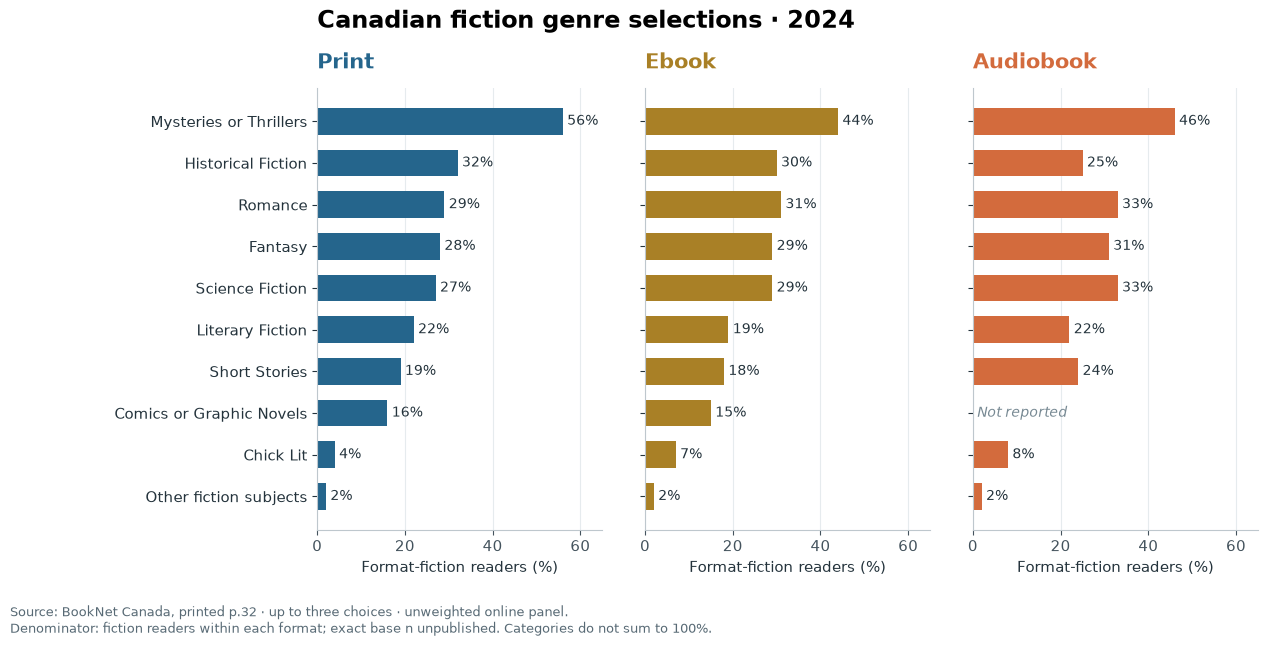

Format,Leading reported genre,Selected (%)
Audiobook,Mysteries or Thrillers,46
Ebook,Mysteries or Thrillers,44
Print,Mysteries or Thrillers,56


The same genre leads all three reported format lists. Format-specific differences may reflect different reader populations, preferences and survey routing; they are not an effect of converting a book to audio.

In [12]:
canada = genres[(genres.country_iso3 == "CAN") & (genres.genre_scope == "Book fiction genres")]
canada_matrix = canada.pivot(index="genre", columns="format_label", values="participation")
canada_matrix = canada_matrix.loc[canada_matrix.Print.sort_values(ascending=False).index]
fig, axes = plt.subplots(1, 3, figsize=(12.8, 6.5), sharey=True)
genre_labels = ["\n".join(textwrap.wrap(label, 24)) for label in canada_matrix.index]
for ax, label in zip(axes, ["Print", "Ebook", "Audiobook"]):
    series = canada_matrix[label]
    positions = np.arange(len(series))
    reported = series.notna().to_numpy()
    ax.barh(positions[reported], series.iloc[reported], color=COLORS[label], height=0.64)
    for y, value in enumerate(series):
        if pd.isna(value):
            ax.text(1, y, "Not reported", va="center", fontsize=10, color=GREY, style="italic")
        else:
            ax.text(value + 1, y, f"{value:.0f}%", va="center", fontsize=10, color=INK)
    ax.set_title(label, loc="left", color=COLORS[label], pad=14)
    ax.set_xlim(0, 65)
    ax.set_xticks([0, 20, 40, 60])
    ax.set_xlabel("Format-fiction readers (%)")
    ax.xaxis.grid(True)
    ax.set_axisbelow(True)
axes[0].set_yticks(range(len(genre_labels)), genre_labels)
axes[0].invert_yaxis()
fig.suptitle("Canadian fiction genre selections · 2024", x=0.25, ha="left", fontsize=17, fontweight="bold")
fig.subplots_adjust(left=0.25, right=0.985, top=0.86, bottom=0.18, wspace=0.15)
finish_figure(fig, "07_canada_genres",
              "Source: BookNet Canada, printed p.32 · up to three choices · unweighted online panel.\n"
              "Denominator: fiction readers within each format; exact base n unpublished. Categories do not sum to 100%.")
leading_genres = canada.dropna(subset=["participation"]).sort_values("participation", ascending=False)
leaders = leading_genres.groupby("format_label").head(1).sort_values("format_label")
display(leaders[["format_label", "genre", "participation"]].rename(columns={
    "format_label": "Format", "genre": "Leading reported genre", "participation": "Selected (%)"
}).style.hide(axis="index").format({"Selected (%)": "{:.0f}"}))
display(Markdown("The same genre leads all three reported format lists. Format-specific differences "
                 "may reflect different reader populations, preferences and survey routing; they are not "
                 "an effect of converting a book to audio."))

### 11. Canadian non-fiction subjects by format

This is a separate BookNet question and reader base: non-fiction readers within each format.
We retain all ten published subjects and the missing audiobook comics/graphic-novel entry.
Subject choices can overlap, and exact subgroup sample sizes are unpublished. Fiction and
non-fiction percentages are not added or treated as sharing the same denominator.

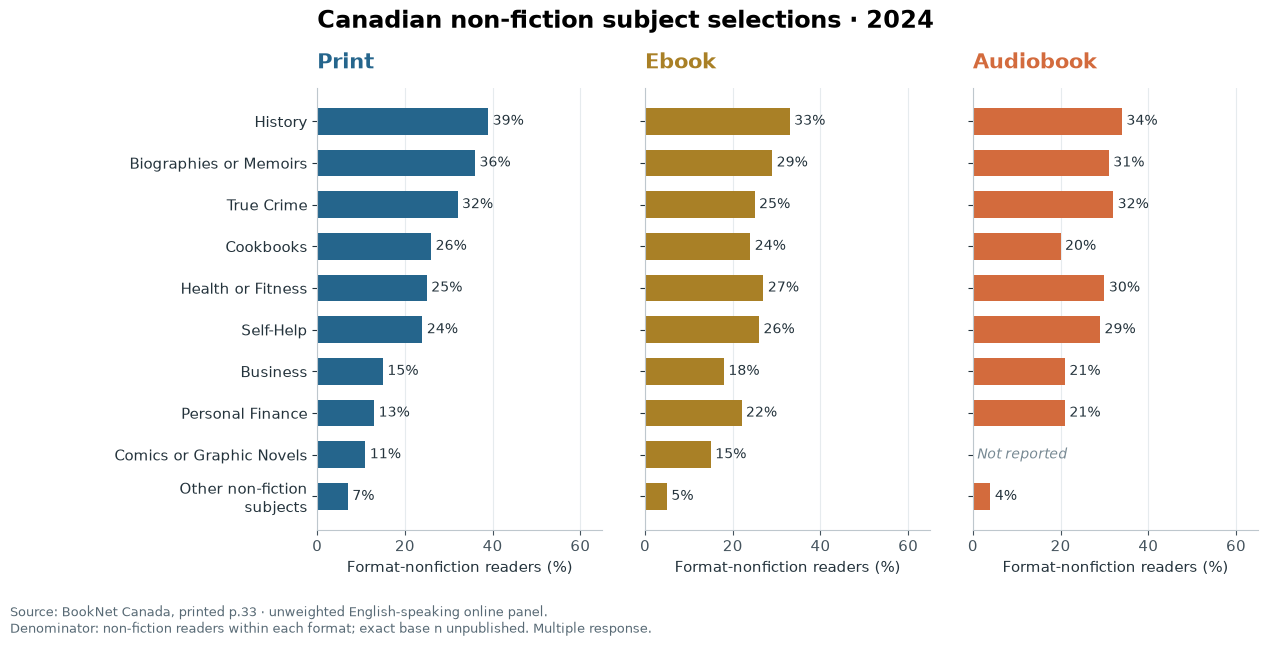

Format,Leading reported subject,Selected (%)
Audiobook,History,34
Ebook,History,33
Print,History,39


History leads the reported non-fiction lists at 39% for print, 33% for ebooks and 34% for audiobooks. This pattern describes the recruited format-specific readers, rather than all Canadian adults or sales demand.

In [13]:
canada_nonfiction = genres[(genres.country_iso3 == "CAN") &
                            (genres.genre_scope == "Book non-fiction genres")]
nonfiction_matrix = canada_nonfiction.pivot(index="genre", columns="format_label", values="participation")
nonfiction_matrix = nonfiction_matrix.loc[nonfiction_matrix.Print.sort_values(ascending=False).index]
fig, axes = plt.subplots(1, 3, figsize=(12.8, 6.5), sharey=True)
nonfiction_labels = ["\n".join(textwrap.wrap(label, 24)) for label in nonfiction_matrix.index]
for ax, label in zip(axes, ["Print", "Ebook", "Audiobook"]):
    series = nonfiction_matrix[label]
    positions = np.arange(len(series))
    reported = series.notna().to_numpy()
    ax.barh(positions[reported], series.iloc[reported], color=COLORS[label], height=0.64)
    for y, value in enumerate(series):
        if pd.isna(value):
            ax.text(1, y, "Not reported", va="center", fontsize=10, color=GREY, style="italic")
        else:
            ax.text(value + 1, y, f"{value:.0f}%", va="center", fontsize=10, color=INK)
    ax.set_title(label, loc="left", color=COLORS[label], pad=14)
    ax.set_xlim(0, 65)
    ax.set_xticks([0, 20, 40, 60])
    ax.set_xlabel("Format-nonfiction readers (%)")
    ax.xaxis.grid(True)
    ax.set_axisbelow(True)
axes[0].set_yticks(range(len(nonfiction_labels)), nonfiction_labels)
axes[0].invert_yaxis()
fig.suptitle("Canadian non-fiction subject selections · 2024", x=0.25, ha="left", fontsize=17, fontweight="bold")
fig.subplots_adjust(left=0.25, right=0.985, top=0.86, bottom=0.18, wspace=0.15)
finish_figure(fig, "08_canada_nonfiction",
              "Source: BookNet Canada, printed p.33 · unweighted English-speaking online panel.\n"
              "Denominator: non-fiction readers within each format; exact base n unpublished. Multiple response.")
nonfiction_leaders = canada_nonfiction.dropna(subset=["participation"]).sort_values(
    "participation", ascending=False).groupby("format_label").head(1).sort_values("format_label")
display(nonfiction_leaders[["format_label", "genre", "participation"]].rename(columns={
    "format_label": "Format", "genre": "Leading reported subject", "participation": "Selected (%)"
}).style.hide(axis="index").format({"Selected (%)": "{:.0f}"}))
display(Markdown("History leads the reported non-fiction lists at 39% for print, 33% for ebooks and "
                 "34% for audiobooks. This pattern describes the recruited format-specific readers, "
                 "rather than all Canadian adults or sales demand."))

### 12. Singapore: a broader genre question

NLB's 2024 genre question concerns general readers (n=3,657), citizens or permanent residents
aged 20+. It includes websites, social media, books, ebooks and magazines, with a “usually”
recall frame. Its reported genres help describe the local reading environment; they
cannot be placed on the Canadian book-fiction scale or treated as audiobook genre preferences.

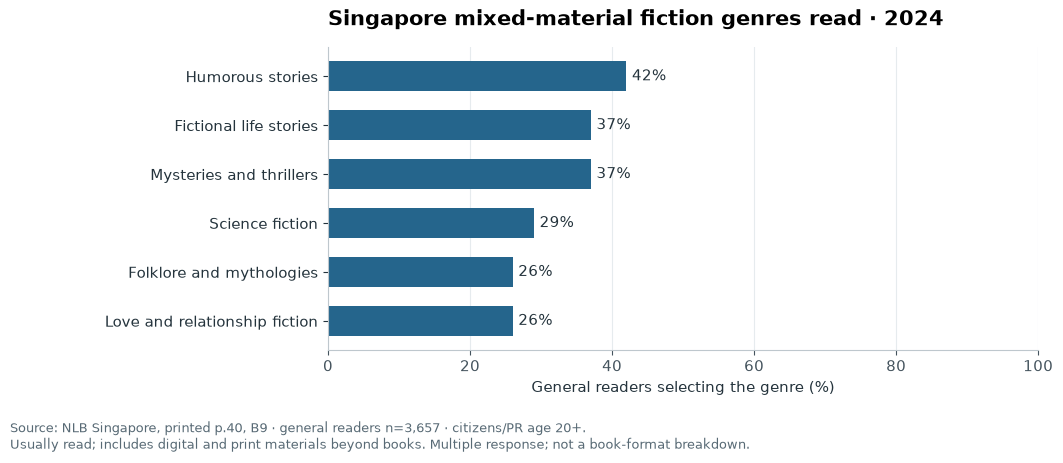

**Humorous stories (42%)** leads this six-category published view. This is a separate question and denominator from Singapore's format-use subset of n=2,693.

In [14]:
singapore = genres[genres.country_iso3 == "SGP"].sort_values("participation")
fig, ax = plt.subplots(figsize=(10.6, 4.8))
labels = ["\n".join(textwrap.wrap(label, 32)) for label in singapore.genre]
ax.barh(labels, singapore.participation, color=BLUE, height=0.62)
for y, value in enumerate(singapore.participation):
    ax.text(value + 0.8, y, f"{value:.0f}%", va="center", fontsize=11, color=INK)
ax.set_xlim(0, 100)
ax.set_xlabel("General readers selecting the genre (%)")
ax.set_title("Singapore mixed-material fiction genres read · 2024", loc="left", pad=16)
ax.xaxis.grid(True)
ax.set_axisbelow(True)
fig.subplots_adjust(left=0.31, right=0.98, top=0.86, bottom=0.23)
finish_figure(fig, "09_singapore_genres",
              "Source: NLB Singapore, printed p.40, B9 · general readers n=3,657 · citizens/PR age 20+.\n"
              "Usually read; includes digital and print materials beyond books. Multiple response; not a book-format breakdown.")
display(Markdown(f"**{singapore.iloc[-1].genre} ({singapore.iloc[-1].participation:.0f}%)** leads this "
                 "six-category published view. This is a separate question and denominator from "
                 "Singapore's format-use subset of n=2,693."))

## Takeaways

1. **Use Europe for country comparisons of total book participation.** Keep the 2022 survey year
   and inclusion of audio visible. The results describe participation, rather than reading volume,
   sales, literacy or current behaviour.
2. **Use within-country demographics for segmentation hypotheses.** The education direction
   persists in a narrower age band, but gaps remain unadjusted. Testing causes would require
   microdata, survey design information and a defensible research design.
3. **Use US history for format adoption during a consistent survey regime.** Treat 2025 as its own
   mode period. More audiobooks and more ebooks can coexist with print because users overlap.
4. **Use national format and genre panels for source-specific profiles.** Canada and Singapore
   offer useful genre observations, while their bases limit generalisation. Genre mappings should preserve
   original labels before any future harmonisation.
5. **Expand coverage by comparable source families.** The worldwide source register is a discovery
   framework, not evidence that every country has comparable observations. Add original survey
   tables and complete the definition/denominator checks before extending rankings.

The next defensible research step is to add national annual format surveys with matching adult
populations and recall periods, then obtain accessible microdata or published design-based intervals
for uncertainty. Predictive modelling should wait for a larger comparable dataset.

### Reproducibility and evidence receipt

The SHA-256 values identify the exact processed inputs used in this run. They detect local
changes, rather than certifying the original surveys. The executed notebook retains all figures,
bounded tables and calculation code. The HTML is a portable reading copy.

In [15]:
receipt = pd.DataFrame([
    {"Input": f"data/processed/{name}", "SHA-256": hashlib.sha256((ROOT / "data/processed" / name).read_bytes()).hexdigest()}
    for name in FILES.values()
])
display(receipt.style.hide(axis="index"))
packages = {name: version(name) for name in ["pandas", "numpy", "scipy", "matplotlib", "nbformat", "nbclient"]}
display(pd.DataFrame([packages]).style.hide(axis="index"))
assert len(figure_paths) == 9
assert all(path.is_file() and path.stat().st_size > 10_000 for path in figure_paths)
display(Markdown("**Run complete:** all notebook checks passed; nine analytical figures were retained inline "
                 "and saved under `outputs/notebook_figures/`. Source-design and coverage limitations remain as stated above."))

Input,SHA-256
data/processed/europe_participation.csv,dc373bb2cf43cd8407afd71f3c2e1b961a188a19b9a2ffd6ff88922f90e7a208
data/processed/europe_demographics.csv,b5be020e3de7801d6a10d0ec8e41ddc3c61d7eec38939b6ce54c33fe890a3c66
data/processed/gender_gaps.csv,fbc36c2d117f13320c2c25f9bec74e990f2c839bea6a42160adf83dca97a9493
data/processed/eu_benchmark.csv,a3d3aa90b1d8959e6cd28b0d05746333010c684af9eec79794eadd03aeda818a
data/processed/us_formats.csv,b2677fe52959707555bb86e58418f6c80f0925d25160eefea1e5f00029b7bcba
data/processed/format_profiles.csv,14fbb92e0680a5abecdd30747b3656b1cd4b8d57d0753efe6f9a3298ba69c2d1
data/processed/genre_profiles.csv,28f2f04f260f1b51c7ba920d8762a3ce8edd4581010e7c023669b3c9ac778dba


pandas,numpy,scipy,matplotlib,nbformat,nbclient
3.0.6,2.5.4,1.18.1,3.11.2,5.11.1,0.11.0


**Run complete:** all notebook checks passed; nine analytical figures were retained inline and saved under `outputs/notebook_figures/`. Source-design and coverage limitations remain as stated above.